# **Recursive Neural Network: precipitations**
La regressione della pioggia giornaliera non ha skill: con la MAE ogni modello converge alla mediana (circa 0 mm) e non batte la baseline "non piove mai" (vedi `rnn.ipynb`). Qui riformuliamo il problema come **classificazione**: per ogni lead time t+1 … t+30 la LSTM stima la **probabilità che piova** (tp ≥ 1 mm). Dalla probabilità si ottiene poi la classe (pioggia sì/no) con una soglia scelta sul validation set.

Metriche:
- **Brier score**: errore quadratico medio tra probabilità prevista ed evento (0/1), più basso è meglio;
- **Brier Skill Score (BSS)**: 1 − Brier / Brier della climatologia (frequenza mensile di pioggia sul train); > 0 significa meglio della climatologia;
- **ROC-AUC**: capacità di distinguere giorni piovosi e secchi, indipendente dalla soglia (0.5 = casuale);
- **reliability diagram**: le probabilità sono calibrate? (es. quando la LSTM dice 30%, piove il 30% delle volte?);
- per la classificazione: accuracy, precision, recall, F1 e **Heidke Skill Score (HSS)**, che misura la skill rispetto a una previsione casuale con la stessa frequenza (0 = nessuna skill).

## IMPORTS AND SETUP

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    GITHUB_USER = "SinghSahiljit44"  # Es. sahiljit
    REPO_NAME = "Weather_forecasting"
    REPO_URL = f"https://github.com/{GITHUB_USER}/{REPO_NAME}.git"

    # Clona la repository se non è già stata clonata nella sessione
    if not os.path.exists(REPO_NAME):
        !git clone {REPO_URL}

    # Cambia la directory di lavoro nella root del progetto
    os.chdir(REPO_NAME)

    # Installa le dipendenze necessarie nell'ambiente di Colab
    %pip install -q -r requirements.txt

    PROJECT_ROOT = Path.cwd()
else:
    # --- CONFIGURAZIONE LOCALE  ---
    PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
    os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print(f" [OK] Ambiente rilevato: {'Google Colab' if IN_COLAB else 'Locale'}")
print(f" [OK] Directory di lavoro impostata a: {Path.cwd()}")

 [OK] Ambiente rilevato: Locale
 [OK] Directory di lavoro impostata a: /home/matteo/Documents/GitHub/Weather_forecasting


In [2]:
import copy
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, brier_score_loss, f1_score, precision_score, recall_score, roc_auc_score
)
from sklearn.preprocessing import StandardScaler

import src.utils.metrics as metrics
from src.data.preprocessing import get_split

RANDOM_STATE = 42
RAIN_THRESHOLD = 1.0  # mm/giorno: sopra questa soglia il giorno è "piovoso"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

/home/matteo/Documents/GitHub/Weather_forecasting/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


## DATASET

In [3]:
split = get_split()
features = split.get_features()

split.define_target("tp_mm")
(X_train, tp_train), (X_val, tp_val), (X_test, tp_test) = split.get(features)

# Target binario: piove (tp >= soglia) a t+1 ... t+30
y_train = (tp_train >= RAIN_THRESHOLD).astype(np.float32)
y_val   = (tp_val   >= RAIN_THRESHOLD).astype(np.float32)
y_test  = (tp_test  >= RAIN_THRESHOLD).astype(np.float32)

x_scaler = StandardScaler().fit(X_train)
X_full = pd.DataFrame(
    x_scaler.transform(split.df[features]),
    index=split.df.index,
    columns=features
)

print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape} | y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape} | y_test:  {y_test.shape}")
print(f"Rainy days (lead 1): train {y_train[1].mean():.1%} | val {y_val[1].mean():.1%} | test {y_test[1].mean():.1%}")

X_train: (10168, 26) | y_train: (10168, 30)
X_val:   (1431, 26) | y_val:   (1431, 30)
X_test:  (1430, 26) | y_test:  (1430, 30)
Rainy days (lead 1): train 25.1% | val 26.0% | test 23.3%


### BASELINE CLIMATOLOGICA
Probabilità di pioggia = frequenza dei giorni piovosi nel mese della data target, stimata sul train. È il riferimento del BSS: un modello utile deve fare meglio della stagionalità.

In [4]:
rain_day = (split.df["tp_mm"] >= RAIN_THRESHOLD).astype(float).where(split.df["tp_mm"].notna())
is_train = rain_day.index.year <= split.TRAIN_END
clim_month = rain_day[is_train].groupby(rain_day.index[is_train].month).mean()


def climatology_proba(y):
    """Per ogni origine t e lead h: frequenza climatologica di pioggia nel mese di t+h."""
    return pd.DataFrame(
        {h: clim_month.reindex((y.index + pd.Timedelta(days=int(h))).month).to_numpy() for h in y.columns},
        index=y.index,
    )


p_clim = {name: climatology_proba(y) for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]}

display(clim_month.rename("P(rain)").to_frame().T.style.format("{:.2f}"))

date,1,2,3,4,5,6,7,8,9,10,11,12
P(rain),0.30,0.34,0.29,0.31,0.23,0.18,0.15,0.14,0.24,0.24,0.27,0.32


## UTILITIES

In [5]:
def make_sequences(X_full, y, seq_len):
    values = X_full.to_numpy(dtype=np.float32)
    windows = np.lib.stride_tricks.sliding_window_view(values, seq_len, axis=0).transpose(0, 2, 1)

    start = X_full.index.get_indexer(y.index) - seq_len + 1
    ok = start >= 0
    X_seq = windows[start[ok]]

    finite = np.isfinite(X_seq).all(axis=(1, 2))  # scarta finestre con NaN (lag/rolling iniziali)
    return X_seq[finite], y.loc[ok].loc[finite]


def prepare_data(seq_len):
    """dict split -> (X_seq, y DataFrame 0/1)."""
    return {
        name: make_sequences(X_full, y, seq_len)
        for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]
    }


def make_loader(X, y, batch_size, shuffle):
    dataset = TensorDataset(torch.from_numpy(X), torch.from_numpy(y.to_numpy(dtype=np.float32, copy=True)))
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

In [6]:
class LSTMClassifier(nn.Module):
    """LSTM + testa lineare: un logit per lead time (probabilità = sigmoid(logit))."""

    def __init__(self, n_features, n_outputs, hidden_size=64, num_layers=1, dropout=0.0):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size, n_outputs)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1])

In [7]:
def set_seed(seed=RANDOM_STATE):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


@torch.no_grad()
def evaluate_loss(model, loader, loss_fn):
    model.eval()
    loss = brier = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        loss += loss_fn(logits, yb).item() * len(xb)
        brier += (torch.sigmoid(logits) - yb).pow(2).mean().item() * len(xb)
    n = len(loader.dataset)
    return loss / n, brier / n


def train_model(model, data, lr=1e-3, weight_decay=0.0, batch_size=64,
                epochs=200, patience=20, trial=None):
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()  # niente pos_weight: le probabilità restano calibrate

    train_loader = make_loader(*data["train"], batch_size, shuffle=True)
    val_loader = make_loader(*data["val"], 1024, shuffle=False)

    history = {"loss": [], "val_loss": [], "brier": [], "val_brier": []}
    best_loss, best_state, wait = np.inf, None, 0

    for epoch in range(epochs):
        model.train()
        run_loss = run_brier = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            loss = loss_fn(logits, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            run_loss += loss.item() * len(xb)
            run_brier += (torch.sigmoid(logits) - yb).pow(2).mean().item() * len(xb)

        n = len(train_loader.dataset)
        val_loss, val_brier = evaluate_loss(model, val_loader, loss_fn)
        history["loss"].append(run_loss / n)
        history["brier"].append(run_brier / n)
        history["val_loss"].append(val_loss)
        history["val_brier"].append(val_brier)

        if trial is not None:
            trial.report(val_loss, step=epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        if val_loss < best_loss:
            best_loss, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return model, history


@torch.no_grad()
def predict_proba(model, X_seq, y_like):
    model.eval()
    loader = DataLoader(TensorDataset(torch.from_numpy(X_seq)), batch_size=1024)
    logits = torch.cat([model(xb.to(DEVICE)).cpu() for (xb,) in loader])
    return pd.DataFrame(torch.sigmoid(logits).numpy(), index=y_like.index, columns=y_like.columns)


def run_config(seq_len=30, hidden_size=64, num_layers=1, dropout=0.0, lr=1e-3,
               weight_decay=0.0, batch_size=64, epochs=200, patience=20, trial=None):
    set_seed()
    data = prepare_data(seq_len)
    model = LSTMClassifier(len(features), y_train.shape[1], hidden_size, num_layers, dropout)
    model, history = train_model(model, data, lr, weight_decay, batch_size, epochs, patience, trial)
    probas = {name: predict_proba(model, X, y) for name, (X, y) in data.items()}
    return model, history, data, probas

In [8]:
def mean_brier(y, p):
    return ((y - p) ** 2).to_numpy().mean()


def brier_skill(y, p, p_ref):
    return 1 - mean_brier(y, p) / mean_brier(y, p_ref)


def mean_auc(y, p):
    return np.mean([roc_auc_score(y[h], p[h]) for h in y.columns])


def heidke(y, y_hat):
    """Heidke Skill Score: skill rispetto a una previsione casuale con la stessa frequenza."""
    y, y_hat = np.asarray(y, dtype=bool), np.asarray(y_hat, dtype=bool)
    a, b = np.sum(y & y_hat), np.sum(~y & y_hat)    # hit, falsi allarmi
    c, d = np.sum(y & ~y_hat), np.sum(~y & ~y_hat)  # mancati, corretti negativi
    den = (a + c) * (c + d) + (a + b) * (b + d)
    return 2 * (a * d - b * c) / den if den else 0.0


def proba_table(splits):
    """splits: {"Val": (y, p, p_clim), ...} -> Brier, BSS e ROC-AUC per lead time."""
    scores = {
        "Brier":   lambda y, p, c: brier_score_loss(y, p),
        "BSS":     lambda y, p, c: 1 - brier_score_loss(y, p) / brier_score_loss(y, c),
        "ROC-AUC": lambda y, p, c: roc_auc_score(y, p),
    }
    table = pd.DataFrame({
        (metric, name): {h: fn(y[h], p[h], c[h]) for h in y.columns}
        for metric, fn in scores.items()
        for name, (y, p, c) in splits.items()
    })
    table.index.name = "Lead time (days)"
    return table


def tune_thresholds(y_val, p_val, grid=np.linspace(0.05, 0.95, 91)):
    """Per ogni lead, soglia di classificazione che massimizza l'HSS sul validation."""
    return pd.Series(
        {h: max(grid, key=lambda t: heidke(y_val[h], p_val[h] >= t)) for h in y_val.columns},
        name="Threshold",
    )


def class_table(y, p, thresholds):
    rows = {}
    for h in y.columns:
        y_true, y_hat = y[h].astype(int), (p[h] >= thresholds[h]).astype(int)
        rows[h] = {
            "Accuracy":  accuracy_score(y_true, y_hat),
            "Precision": precision_score(y_true, y_hat, zero_division=0),
            "Recall":    recall_score(y_true, y_hat, zero_division=0),
            "F1":        f1_score(y_true, y_hat, zero_division=0),
            "HSS":       heidke(y_true, y_hat),
        }
    table = pd.DataFrame(rows).T
    table.index.name = "Lead time (days)"
    return table

In [9]:
def style_axis(ax):
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def plot_by_lead(table, split_name, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric, reference in zip(axes, ["BSS", "ROC-AUC"], [0.0, 0.5]):
        values = table[(metric, split_name)]
        ax.plot(values.index, values.values, color="#2a78d6", linewidth=1.5, marker="o", markersize=4)
        ax.axhline(reference, color="gray", linestyle="--", linewidth=1)
        ax.set_xlabel("Lead time (days)")
        ax.set_ylabel(metric)
        ax.set_title(f"{model_name}: {split_name.lower()} {metric} by lead time", loc="left")
        style_axis(ax)
    plt.tight_layout()
    plt.show()


def plot_reliability(y, p, leads=(1, 3, 7, 14), n_bins=10, title="Reliability diagram"):
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1, label="perfect calibration")
    for h in leads:
        frac_pos, mean_pred = calibration_curve(y[h], p[h], n_bins=n_bins, strategy="quantile")
        ax.plot(mean_pred, frac_pos, marker="o", markersize=4, linewidth=1.5, label=f"lead {h}")
    ax.set_xlabel("Predicted probability")
    ax.set_ylabel("Observed frequency")
    ax.set_title(title, loc="left")
    ax.legend()
    style_axis(ax)
    plt.tight_layout()
    plt.show()


def show_proba_results(model_name, data, probas, splits=("train", "val")):
    table = proba_table({
        s.capitalize(): (data[s][1], probas[s], p_clim[s].loc[data[s][1].index]) for s in splits
    })
    plot_by_lead(table, splits[-1].capitalize(), model_name)
    display(table.style.format("{:.3f}"))
    return table

In [10]:
def evaluate_config(seq_len, hidden_size, num_layers):
    _, history, data, probas = run_config(seq_len=seq_len, hidden_size=hidden_size, num_layers=num_layers)
    y, p = data["val"][1], probas["val"]
    return {
        "seq_len": seq_len,
        "hidden_size": hidden_size,
        "num_layers": num_layers,
        "epochs": len(history["loss"]),
        "Val Brier": mean_brier(y, p),
        "Val BSS": brier_skill(y, p, p_clim["val"].loc[y.index]),
        "Val ROC-AUC": mean_auc(y, p),
    }


def manual_search(seq_lens=(7, 14, 30), hidden_sizes=(32, 64, 128), layers=(1, 2)):
    results = [evaluate_config(s, h, l) for s, h, l in product(seq_lens, hidden_sizes, layers)]
    return pd.DataFrame(results).sort_values("Val Brier").reset_index(drop=True)


def make_objective(seq_lens=(3, 7, 14, 30, 60)):
    def objective(trial):
        params = {
            "seq_len":      trial.suggest_categorical("seq_len", list(seq_lens)),
            "hidden_size":  trial.suggest_int("hidden_size", 16, 256, log=True),
            "num_layers":   trial.suggest_int("num_layers", 1, 3),
            "dropout":      trial.suggest_float("dropout", 0.0, 0.5),
            "lr":           trial.suggest_float("lr", 1e-4, 1e-2, log=True),
            "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
            "batch_size":   trial.suggest_categorical("batch_size", [32, 64, 128, 256]),
        }
        _, _, data, probas = run_config(trial=trial, **params)
        return mean_brier(data["val"][1], probas["val"])
    return objective


def run_study(n_trials=50, **objective_kwargs):
    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=10)
    )
    study.optimize(make_objective(**objective_kwargs), n_trials=n_trials, show_progress_bar=True)

    print("Best validation Brier:", study.best_value)
    print("Best hyperparameters:", study.best_params)
    display(study.trials_dataframe().sort_values("value")[["number", "value", "state"]].head(10))
    return study

## **LSTM**

### DEFAULT PERFORMANCE

Epochs: 21


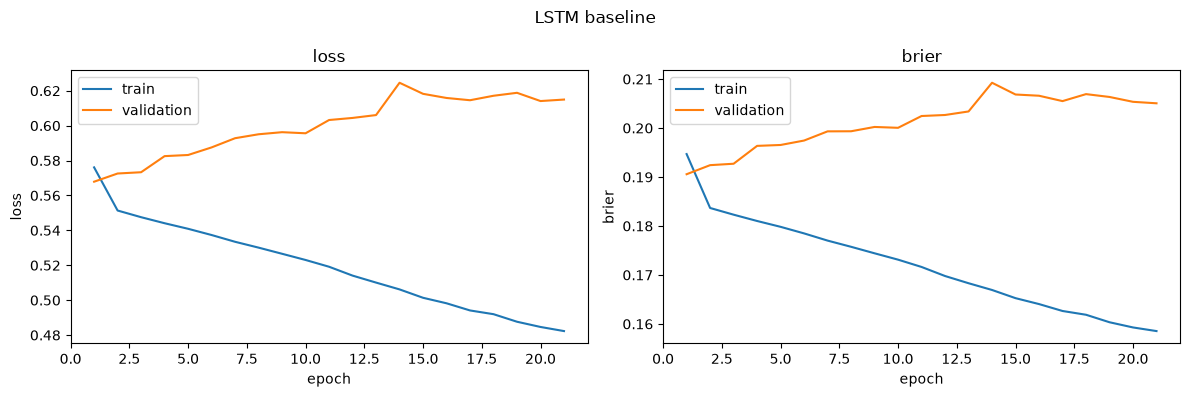

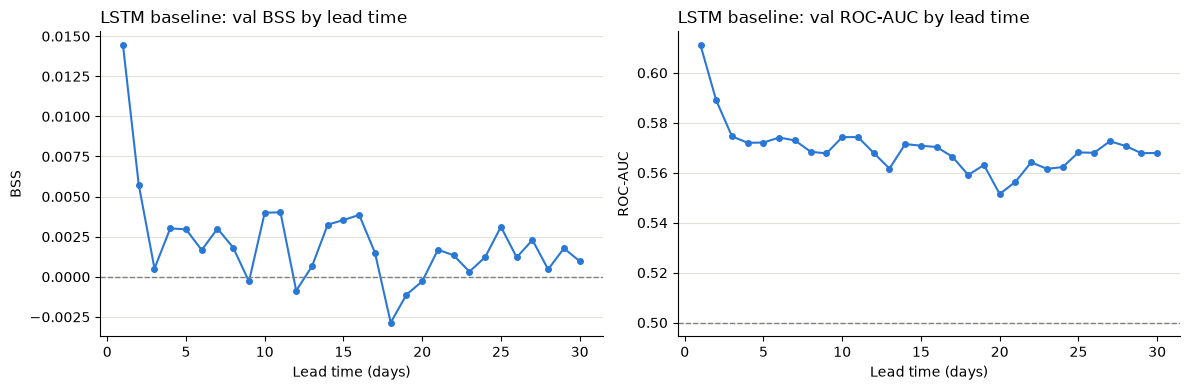

In [11]:
lstm, history, data, probas = run_config()

print(f"Epochs: {len(history['loss'])}")
metrics.plot_training_history(history, metric="brier", title="LSTM baseline")
show_proba_results("LSTM baseline", data, probas);

### MANUAL HYPERPARAMETER SEARCH

In [12]:
results_lstm = manual_search()
display(results_lstm.round(4))

,seq_len,hidden_size,num_layers,epochs,Val Brier,Val BSS,Val ROC-AUC
0,30,128,2,21,0.1903,0.0034,0.5734
1,30,128,1,21,0.1904,0.0028,0.5725
2,30,32,1,21,0.1905,0.0025,0.5715
3,7,128,1,21,0.1905,0.0025,0.5729
4,14,128,1,21,0.1905,0.0022,0.5731
5,7,32,1,21,0.1906,0.0022,0.5711
6,30,64,1,21,0.1906,0.0021,0.5698
7,30,32,2,21,0.1906,0.0020,0.5695
8,14,32,2,21,0.1907,0.0016,0.5672
9,14,32,1,21,0.1907,0.0014,0.5680


### OPTUNA
Obiettivo: Brier medio sul validation (30 lead time). Il Brier è una *proper scoring rule*: viene minimizzato solo da probabilità corrette e calibrate.

In [13]:
study_lstm = run_study(n_trials=50)

[I 2026-11-28 15:30:57,844] A new study created in memory with name: no-name-edc7556e-8974-4893-b261-5a4f4499d9be
Best trial: 0. Best value: 0.191021:   2%|▏         | 1/50 [00:07<05:49,  7.14s/it]

[I 2026-11-28 15:31:04,984] Trial 0 finished with value: 0.19102147221565247 and parameters: {'seq_len': 7, 'hidden_size': 24, 'num_layers': 1, 'dropout': 0.4330880728874676, 'lr': 0.0015930522616241021, 'weight_decay': 0.000133112160807369, 'batch_size': 64}. Best is trial 0 with value: 0.19102147221565247.


Best trial: 1. Best value: 0.190842:   4%|▍         | 2/50 [00:14<05:59,  7.48s/it]

[I 2026-11-28 15:31:12,703] Trial 1 finished with value: 0.19084212183952332 and parameters: {'seq_len': 30, 'hidden_size': 35, 'num_layers': 2, 'dropout': 0.06974693032602092, 'lr': 0.0003839629299804173, 'weight_decay': 1.2562773503807034e-05, 'batch_size': 64}. Best is trial 1 with value: 0.19084212183952332.


Best trial: 1. Best value: 0.190842:   6%|▌         | 3/50 [00:36<11:01, 14.07s/it]

[I 2026-11-28 15:31:34,612] Trial 2 finished with value: 0.19127126038074493 and parameters: {'seq_len': 14, 'hidden_size': 222, 'num_layers': 3, 'dropout': 0.40419867405823057, 'lr': 0.0004066563313514797, 'weight_decay': 1.9634341572933354e-06, 'batch_size': 32}. Best is trial 1 with value: 0.19084212183952332.


... (91 outputs left out)

[I 2026-11-28 15:34:50,633] Trial 48 finished with value: 0.19019541144371033 and parameters: {'seq_len': 3, 'hidden_size': 146, 'num_layers': 3, 'dropout': 0.0693170363090407, 'lr': 0.0004845716258071185, 'weight_decay': 0.000646993637534627, 'batch_size': 256}. Best is trial 28 with value: 0.1900792270898819.


Best trial: 28. Best value: 0.190079: 100%|██████████| 50/50 [03:56<00:00,  4.73s/it]

[I 2026-11-28 15:34:54,395] Trial 49 finished with value: 0.19028009474277496 and parameters: {'seq_len': 3, 'hidden_size': 62, 'num_layers': 3, 'dropout': 0.07135213253920393, 'lr': 0.0033120442687276453, 'weight_decay': 0.0005137965815272731, 'batch_size': 256}. Best is trial 28 with value: 0.1900792270898819.
Best validation Brier: 0.1900792270898819
Best hyperparameters: {'seq_len': 3, 'hidden_size': 78, 'num_layers': 3, 'dropout': 0.15140184801613984, 'lr': 0.002436503435920429, 'weight_decay': 0.0007782303629498094, 'batch_size': 256}


,number,value,state
28,28,0.190079,COMPLETE
42,42,0.190101,COMPLETE
34,34,0.190108,COMPLETE
43,43,0.190112,COMPLETE
38,38,0.190115,COMPLETE
37,37,0.190122,COMPLETE
29,29,0.190127,COMPLETE
41,41,0.190134,COMPLETE
45,45,0.190145,COMPLETE
26,26,0.190147,COMPLETE


### TESTING

#### PROBABILITÀ

Best hyperparameters: {'seq_len': 3, 'hidden_size': 78, 'num_layers': 3, 'dropout': 0.15140184801613984, 'lr': 0.002436503435920429, 'weight_decay': 0.0007782303629498094, 'batch_size': 256}


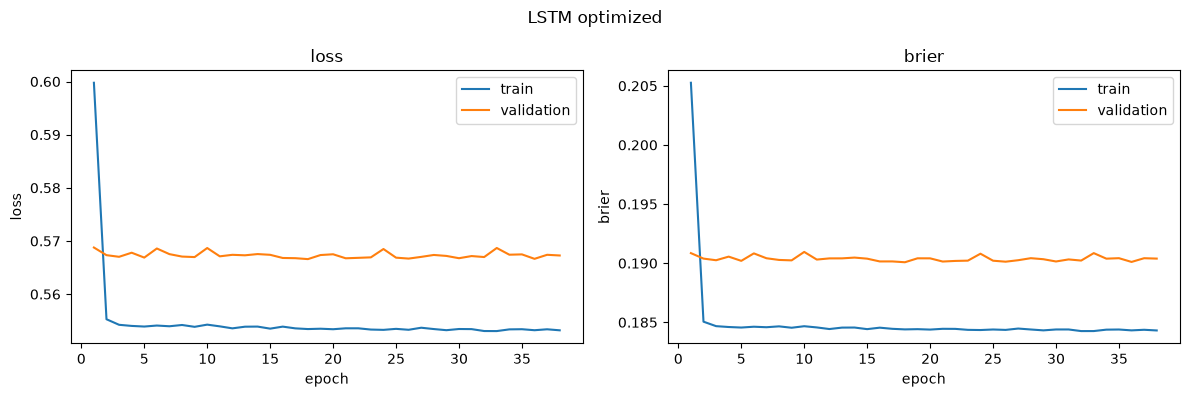

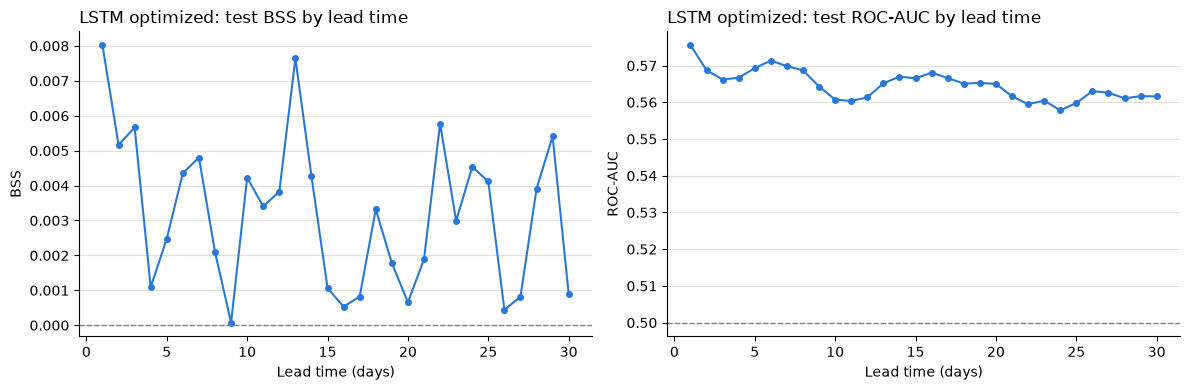

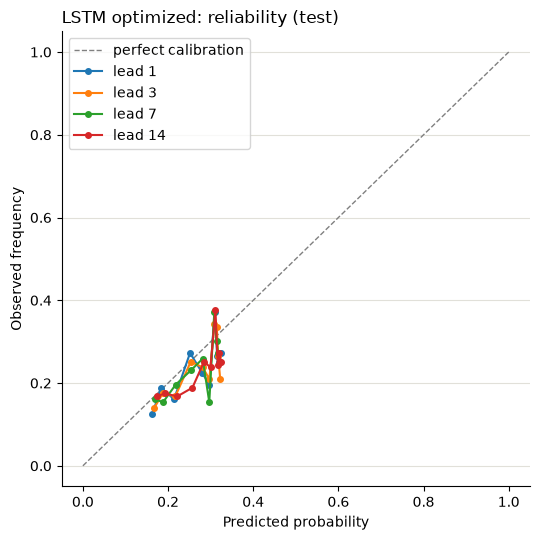

In [18]:
best_params = study_lstm.best_params
print("Best hyperparameters:", best_params)

lstm, history, data, probas = run_config(**best_params)

metrics.plot_training_history(history, metric="brier", title="LSTM optimized")
proba_results = show_proba_results("LSTM optimized", data, probas, splits=("train", "val", "test"))
plot_reliability(data["test"][1], probas["test"], title="LSTM optimized: reliability (test)")

#### CLASSIFICAZIONE
La classe si ottiene confrontando la probabilità con una soglia. La soglia è scelta per ogni lead sul **validation**, massimizzando l'HSS, e poi applicata al test. Una soglia fissa a 0.5 non va bene: i giorni piovosi sono la minoranza e le probabilità ai lead lunghi restano vicine alla frequenza climatologica.

In [15]:
thresholds = tune_thresholds(data["val"][1], probas["val"])

class_results = pd.concat(
    {s.capitalize(): class_table(data[s][1], probas[s], thresholds) for s in ("train", "val", "test")},
    axis=1,
)
class_results[("", "Threshold")] = thresholds

display(class_results.style.format("{:.3f}"))

## COMPARISON
Confronto sul test con due baseline: la **climatologia** (frequenza mensile, soglie scelte sul validation come per la LSTM) e la **persistenza** (domani piove se oggi è piovuto, soglia 0.5).

In [19]:
y_te = data["test"][1]
rain_today = (split.df["tp_mm"] >= RAIN_THRESHOLD).astype(float)

candidates = {
    "LSTM": (probas["test"], thresholds),
    "Climatology (monthly frequency)": (
        p_clim["test"].loc[y_te.index],
        tune_thresholds(data["val"][1], p_clim["val"].loc[data["val"][1].index]),
    ),
    "Persistence (rain today)": (
        pd.DataFrame({h: rain_today.loc[y_te.index].to_numpy() for h in y_te.columns}, index=y_te.index),
        pd.Series(0.5, index=y_te.columns),
    ),
}

comparison = pd.DataFrame([
    {
        "Model": name,
        "Brier": mean_brier(y_te, p),
        "BSS": brier_skill(y_te, p, p_clim["test"].loc[y_te.index]),
        "ROC-AUC": mean_auc(y_te, p),
        "HSS": class_table(y_te, p, thr)["HSS"].mean(),
        "F1": class_table(y_te, p, thr)["F1"].mean(),
    }
    for name, (p, thr) in candidates.items()
]).sort_values("Brier").reset_index(drop=True)

comparison.index += 1
comparison.index.name = "Rank"
display(comparison.style.format({c: "{:.4f}" for c in ["Brier", "BSS", "ROC-AUC", "HSS", "F1"]}))

,Model,Brier,BSS,ROC-AUC,HSS,F1
Rank,,,,,,
1,LSTM,0.1785,0.0032,0.5647,0.0854,0.3857
2,Climatology (monthly frequency),0.1791,0.0000,0.5393,0.0917,0.3785
3,Persistence (rain today),0.3479,-0.9423,0.5140,0.0281,0.2550


In [20]:
# Skill per lead time sul test: dove la LSTM batte la climatologia?
leads = [1, 2, 3, 5, 7, 14, 30]
display(
    pd.concat(
        {
            "BSS": proba_results[("BSS", "Test")],
            "ROC-AUC": proba_results[("ROC-AUC", "Test")],
            "HSS": class_results[("Test", "HSS")],
        },
        axis=1,
    ).loc[leads].style.format("{:.3f}")
)

,BSS,ROC-AUC,HSS
Lead time (days),,,
1,0.008,0.576,0.077
2,0.005,0.569,0.091
3,0.006,0.566,0.078
5,0.002,0.569,0.089
7,0.005,0.570,0.070
14,0.004,0.567,0.076
30,0.001,0.562,0.108
